# Direct Coupler (transmon-transmon)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/qiskit-community/qiskit-metal/blob/main/docs/circuit-examples/D.Qubit-couplers/32-TwoTransmonsDirectCoupling.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/qiskit-community/qiskit-metal/main?labpath=docs%2Fcircuit-examples%2FD.Qubit-couplers%2F32-TwoTransmonsDirectCoupling.ipynb)

> 💡 **Running in Colab or Binder?** Skip the desktop GUI install — the cell below grabs the lite (no-Qt) wheel, and `qm.gui(design)` auto-picks an inline matplotlib viewer with the same API (`gui.rebuild()`, `gui.screenshot()`, `gui.edit_component(...)`) as the desktop `MetalGUI`.

In [1]:
import qiskit_metal as metal
from qiskit_metal import designs, MetalGUI, Dict

In [2]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
# !pip install -q quantum-metal

> 💡 **Using this tutorial without the Qt GUI**
> 
> This tutorial uses the desktop `MetalGUI`. To follow along on Colab, Binder, JupyterHub, or any environment where Qt isn't available, **replace any `gui.rebuild()` / `gui.screenshot()` call with `qm.view(design)`** — it renders the design to a matplotlib `Figure` you can display inline or save with `fig.savefig(...)`.
> 
> See [1.1 Quick start](https://qiskit-community.github.io/qiskit-metal/tut/1-Overview/1.1-Quick-start.html) for a complete runnable walkthrough and [`docs/headless-usage.rst`](https://qiskit-community.github.io/qiskit-metal/headless-usage.html) for the full reference.

### Create the design in Metal
Setup a design of a given dimension. Dimensions will be respected in the design rendering. <br>
The chip is centred on the origin: it spans ±size_x/2 and ±size_y/2.

In [3]:
design = designs.DesignPlanar({}, True)
design.chips.main.size["size_x"] = "2mm"
design.chips.main.size["size_y"] = "2mm"

gui = MetalGUI(design)

Create two transmons joined by a short direct coupler: a `RouteStraight` between their `readout` pads. The pair is placed symmetrically about the chip centre.

In [4]:
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight

# Just FYI, RoutePathFinder is another QComponent that could have been used instead of RouteStraight.

In [5]:
# Be aware of the options for TransmonPocket
TransmonPocket.get_template_options(design)

{'pos_x': '0.0um',
 'pos_y': '0.0um',
 'orientation': '0.0',
 'chip': 'main',
 'layer': '1',
 'connection_pads': {},
 '_default_connection_pads': {'pad_gap': '15um',
  'pad_width': '125um',
  'pad_height': '30um',
  'pad_cpw_shift': '5um',
  'pad_cpw_extent': '25um',
  'cpw_width': 'cpw_width',
  'cpw_gap': 'cpw_gap',
  'cpw_extend': '100um',
  'pocket_extent': '5um',
  'pocket_rise': '65um',
  'loc_W': '+1',
  'loc_H': '+1'},
 'pad_gap': '30um',
 'inductor_width': '20um',
 'pad_width': '455um',
 'pad_height': '90um',
 'pocket_width': '650um',
 'pocket_height': '650um',
 'gds_cell_name': 'my_other_junction'}

In [6]:
RouteStraight.get_template_options(design)

{'chip': 'main',
 'layer': '1',
 'pin_inputs': {'start_pin': {'component': '', 'pin': ''},
  'end_pin': {'component': '', 'pin': ''}},
 'fillet': '0',
 'lead': {'start_straight': '0mm',
  'end_straight': '0mm',
  'start_jogged_extension': '',
  'end_jogged_extension': ''},
 'total_length': '7mm',
 'trace_width': 'cpw_width'}

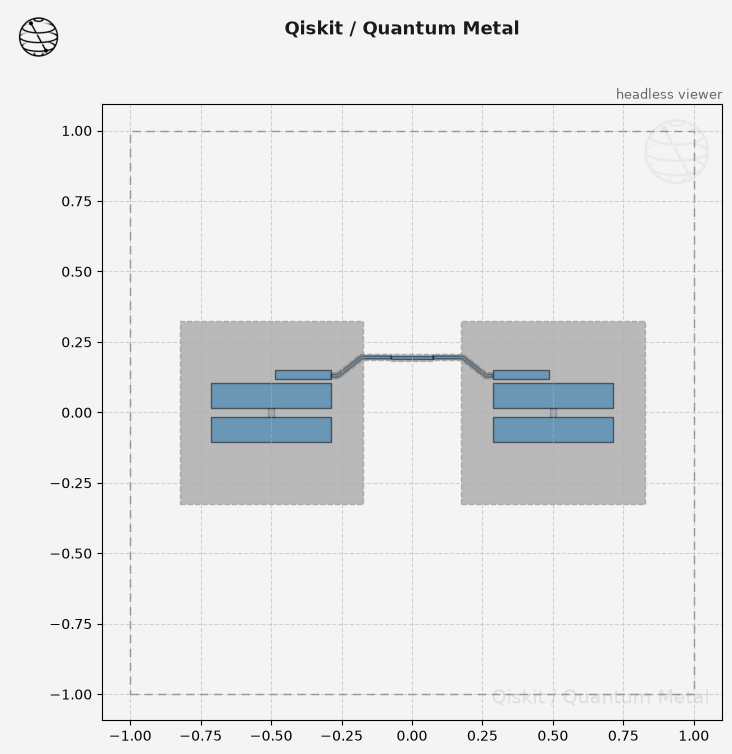

In [7]:
q1 = TransmonPocket(
    design,
    "Q1",
    options=dict(
        pos_x="-0.5 mm",
        pad_width="425 um",
        pocket_height="650um",
        connection_pads=dict(readout=dict(loc_W=+1, loc_H=+1, pad_width="200um")),
    ),
)

q2 = TransmonPocket(
    design,
    "Q2",
    options=dict(
        pos_x="+0.5 mm",
        pad_width="425 um",
        pocket_height="650um",
        connection_pads=dict(readout=dict(loc_W=-1, loc_H=+1, pad_width="200um")),
    ),
)

bus = RouteStraight(
    design,
    "coupler",
    Dict(
        pin_inputs=Dict(
            start_pin=Dict(component="Q1", pin="readout"),
            end_pin=Dict(component="Q2", pin="readout"),
        ),
    ),
)

gui.rebuild()
gui.autoscale()

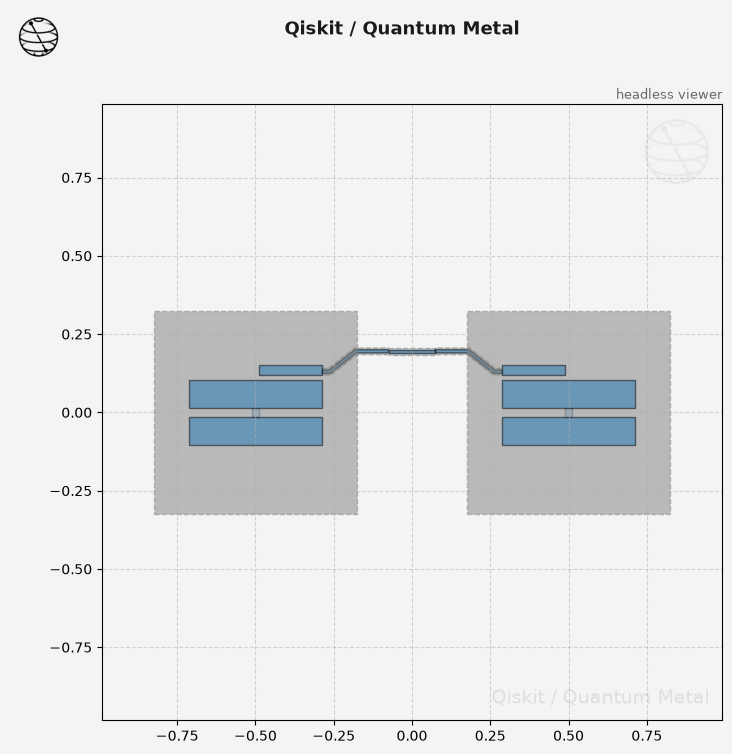

In [8]:
# Get a list of all the qcomponents in QDesign and then zoom on them.
all_component_names = design.components.keys()

gui.zoom_on_components(all_component_names)

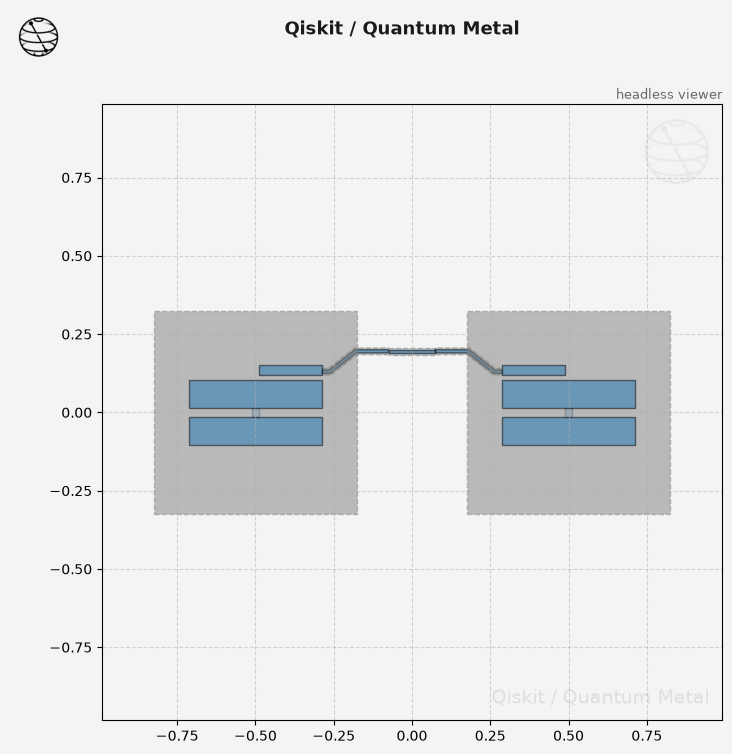

In [9]:
# Save screenshot as a .png formatted file.
gui.screenshot()

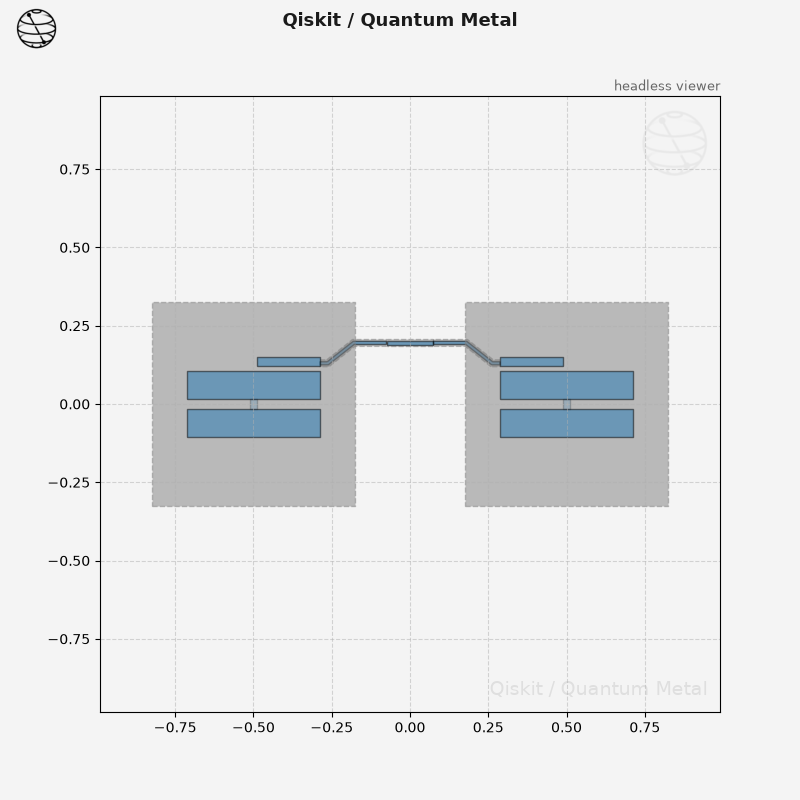

In [10]:
# Screenshot the canvas only as a .png formatted file.
gui.figure.savefig("shot.png")

from IPython.display import Image, display

_disp_ops = dict(width=500)
display(Image("shot.png", **_disp_ops))

Check the layout with the design-rule checker (tutorial 2.24): every component must lie on the chip.

In [11]:
from qiskit_metal.validation import validate

print(validate(design).report())

Design rules passed (11 rules ran, no findings).


In [12]:
# Closing the Qiskit Metal GUI
gui.main_window.close()